# Task 2: FX exposure analysis with SQL

A guided, executed notebook. Start with LEARNING_GUIDE.md. Rates through 9 October 2026; illustrative client exposures.

## 1. Imports and project settings

We value an illustrative fixed foreign-currency cash portfolio in USD. The market data is public; the balances are invented. Run from this project folder.

In [1]:
"""Task 2: FX exposure analytics with SQL. Run from the extracted project.
This reproduces a fixed public-data snapshot. No internet is needed to run it.
"""
from pathlib import Path
import sqlite3
import json
import hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
START, END = '2020-01-01', '2026-10-13'
SOURCE = DATA / 'fred_fx_snapshot.csv'
SERIES = {'DEXUSEU': 'EUR', 'DEXUSUK': 'GBP', 'DEXJPUS': 'JPY'}
EXPOSURES = {'EUR': 10_000_000.0, 'GBP': 5_000_000.0, 'JPY': 1_000_000_000.0}
print('Illustrative constant cash balances:', EXPOSURES)



Illustrative constant cash balances: {'EUR': 10000000.0, 'GBP': 5000000.0, 'JPY': 1000000000.0}


## 2. Preserve missing values and validate the source

Keep raw missing values visible. Use the same complete dates for all currencies, and reject malformed or nonpositive rates.

In [2]:
raw = pd.read_csv(SOURCE, na_values=['.'])
date_col = next((c for c in ['observation_date', 'DATE'] if c in raw), None)
if date_col is None or not set(SERIES).issubset(raw.columns):
    raise ValueError('Unexpected source schema')
raw = raw.rename(columns={date_col: 'date'})
raw['date'] = pd.to_datetime(raw['date'], errors='raise')
if raw['date'].isna().any():
    raise ValueError('Missing dates')
raw = raw.loc[raw['date'].between(START, END), ['date', *SERIES]].copy()
raw = raw.sort_values('date').reset_index(drop=True)
if raw.empty or raw['date'].duplicated().any():
    raise ValueError('Empty date range or duplicate dates')
for series in SERIES:
    raw[series] = pd.to_numeric(raw[series], errors='raise')
    valid = raw[series].dropna()
    if not np.isfinite(valid).all() or not (valid > 0).all():
        raise ValueError(f'Invalid rate in {series}')

complete_mask = raw[list(SERIES)].notna().all(axis=1)
paired = raw.loc[complete_mask].copy().reset_index(drop=True)
if len(paired) < 22:
    raise ValueError('Insufficient common history for 21-observation changes')
raw.loc[~complete_mask].to_csv(OUT / 'excluded_dates.csv', index=False)
qc = {
    'requested_start': START, 'requested_end': END,
    'source_rows_in_period': len(raw), 'complete_common_dates': len(paired),
    'excluded_dates': int((~complete_mask).sum()),
    'missing_by_series': {s: int(raw[s].isna().sum()) for s in SERIES},
    'duplicate_dates': int(raw['date'].duplicated().sum()),
    'first_complete_date': str(paired['date'].min().date()),
    'last_complete_date': str(paired['date'].max().date()),
    'source_sha256': hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
    'run_utc': datetime.now(timezone.utc).isoformat(),
}
print(json.dumps(qc, indent=2))



{
  "requested_start": "2020-01-01",
  "requested_end": "2026-10-13",
  "source_rows_in_period": 1768,
  "complete_common_dates": 1694,
  "excluded_dates": 74,
  "missing_by_series": {
    "DEXUSEU": 74,
    "DEXUSUK": 74,
    "DEXJPUS": 74
  },
  "duplicate_dates": 0,
  "first_complete_date": "2020-01-02",
  "last_complete_date": "2026-10-09",
  "source_sha256": "3f0a285f000b03bc24e3159b2e3c947dac37df513dafcd03444cf1e0402a24cc",
  "run_utc": "2026-10-14T00:50:53.731160+00:00"
}


## 3. Load typed tables into SQLite

SQL schema uses keys and constraints. Read sql/analysis.sql: CASE handles quote direction, LAG obtains prior values and JOIN brings in holdings.

In [3]:
conn = sqlite3.connect(OUT / 'fx_monitor.sqlite')
conn.executescript((ROOT / 'sql/schema.sql').read_text())
conn.executemany('INSERT INTO currencies VALUES (?, ?, ?)', [
    ('EUR', 'DEXUSEU', 'USD_PER_FCY'),
    ('GBP', 'DEXUSUK', 'USD_PER_FCY'),
    ('JPY', 'DEXJPUS', 'FCY_PER_USD'),
])
conn.executemany('INSERT INTO exposures VALUES (?, ?)', list(EXPOSURES.items()))

long_raw = raw.melt(id_vars='date', var_name='series', value_name='raw_rate')
records = [
    (d.strftime('%Y-%m-%d'), SERIES[s], None if pd.isna(v) else float(v))
    for d, s, v in long_raw.itertuples(index=False, name=None)
]
conn.executemany('INSERT INTO raw_fx VALUES (?, ?, ?)', records)
conn.commit()
conn.executescript((ROOT / 'sql/analysis.sql').read_text())
monitor = pd.read_sql_query((ROOT / 'sql/client_monitor.sql').read_text(), conn)
normalized = pd.read_sql_query('SELECT * FROM normalized_fx ORDER BY date, currency', conn)
normalized['date'] = pd.to_datetime(normalized['date'])
print('\nSQL tables loaded. Latest monitor:')
print(monitor[['previous_date', 'date', 'observations', 'currency',
               'fx_return_pct', 'fx_translation_change_usd']].round(4).to_string(index=False))




SQL tables loaded. Latest monitor:
previous_date       date  observations currency  fx_return_pct  fx_translation_change_usd
   2026-10-08 2026-10-09             1      EUR         0.0089                  1000.0000
   2026-10-08 2026-10-09             1      GBP         0.1363                  9000.0000
   2026-10-08 2026-10-09             1      JPY        -0.0063                  -398.8836
   2026-10-02 2026-10-09             5      EUR        -0.5862                -66000.0000
   2026-10-02 2026-10-09             5      GBP        -0.0378                 -2500.0000
   2026-10-02 2026-10-09             5      JPY        -0.3347                -21210.4904
   2026-09-10 2026-10-09            21      EUR        -3.7492               -436000.0000
   2026-09-10 2026-10-09            21      GBP        -2.2391               -151500.0000
   2026-09-10 2026-10-09            21      JPY        -2.7030               -175453.9843


## 4. Independently reconcile SQL against pandas

Independently calculate the same quantities in pandas. Matching SQL and Python results checks implementation, not full source correctness.

In [4]:
px = paired.set_index('date')[list(SERIES)].rename(columns=SERIES)
px['JPY'] = 1.0 / px['JPY']
sql_px = normalized.pivot(index='date', columns='currency', values='usd_per_fcy')
pd.testing.assert_frame_equal(px.sort_index(axis=1), sql_px.sort_index(axis=1),
                              check_names=False, check_dtype=False, rtol=1e-12, atol=1e-12)
expected_rows = []
for h in [1, 5, 21]:
    for c, amount in EXPOSURES.items():
        now, before = px[c].iloc[-1], px[c].iloc[-1-h]
        expected_rows.append({
            'observations': h, 'currency': c,
            'previous_date': px.index[-1-h].strftime('%Y-%m-%d'),
            'fx_return_pct': 100 * (now / before - 1),
            'previous_value_usd': amount * before,
            'current_value_usd': amount * now,
            'fx_translation_change_usd': amount * (now-before),
        })
expected = pd.DataFrame(expected_rows).set_index(['observations', 'currency']).sort_index()
actual = monitor.set_index(['observations', 'currency']).sort_index()
pd.testing.assert_frame_equal(actual[expected.columns], expected,
                              check_dtype=False, rtol=1e-10, atol=1e-7)
if len(monitor) != 9 or monitor.duplicated(['observations', 'currency']).any():
    raise ValueError('Unexpected row count or duplicated exposure join')
np.testing.assert_allclose(
    monitor['current_value_usd'] - monitor['previous_value_usd'],
    monitor['fx_translation_change_usd'], rtol=1e-10, atol=1e-7)
qc['sql_python_reconciliation'] = 'PASS: all normalized dates and all nine monitor rows'
(OUT / 'quality_report.json').write_text(json.dumps(qc, indent=2), encoding='utf-8')
print('\nPASS: SQL normalization, comparison dates, returns and valuation reconcile with pandas.')




PASS: SQL normalization, comparison dates, returns and valuation reconcile with pandas.


## 5. Aggregate client exposure without averaging currency returns

Add dollar contributions, then divide by combined starting USD value. An unweighted mean of currency returns would be incorrect.

In [5]:
totals = monitor.groupby(['observations', 'previous_date', 'date'], as_index=False).agg(
    previous_value_usd=('previous_value_usd', 'sum'),
    current_value_usd=('current_value_usd', 'sum'),
    fx_translation_change_usd=('fx_translation_change_usd', 'sum'),
)
totals['portfolio_fx_return_pct'] = (
    100 * totals['fx_translation_change_usd'] / totals['previous_value_usd'])
monitor.to_csv(OUT / 'client_monitor.csv', index=False)
totals.to_csv(OUT / 'portfolio_summary.csv', index=False)
normalized.to_csv(OUT / 'normalized_fx.csv', index=False)
print('\nIllustrative portfolio totals:')
print(totals.round(4).to_string(index=False))




Illustrative portfolio totals:
 observations previous_date       date  previous_value_usd  current_value_usd  fx_translation_change_usd  portfolio_fx_return_pct
            1    2026-10-08 2026-10-09        2.411342e+07       2.412302e+07                  9601.1164                   0.0398
            5    2026-10-02 2026-10-09        2.421273e+07       2.412302e+07                -89710.4904                  -0.3705
           21    2026-09-10 2026-10-09        2.488598e+07       2.412302e+07               -762953.9843                  -3.0658


## 6. Build a client-facing chart

Currencies are indexed to 100 for comparison. Weekly dollar contributions depend on both percentage movement and position size.

In [6]:
AS_OF = px.index[-1].strftime('%Y-%m-%d')
recent = px.loc[px.index >= px.index[-1] - pd.DateOffset(months=3)]
index_values = 100 * recent / recent.iloc[0]
weekly = monitor.loc[monitor['observations'] == 5].set_index('currency').loc[list(EXPOSURES)]
colors = {'EUR': '#2563EB', 'GBP': '#0F766E', 'JPY': '#9333EA'}
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={'width_ratios':[1.35, 1]})
for c in EXPOSURES:
    axes[0].plot(index_values.index, index_values[c], label=c, color=colors[c], linewidth=2)
axes[0].axhline(100, color='#64748B', linewidth=1, linestyle='--')
axes[0].set_title('Foreign currencies: USD value per unit', loc='left', fontsize=12)
axes[0].set_ylabel(f'Index: {recent.index[0]:%d %b %Y} = 100')
axes[0].xaxis.set_major_locator(mdates.MonthLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0].legend(frameon=False, ncol=3)
bars = axes[1].bar(weekly.index, weekly['fx_translation_change_usd']/1000,
                  color=[colors[c] for c in weekly.index], width=0.55)
axes[1].axhline(0, color='#64748B', linewidth=1)
axes[1].bar_label(bars, labels=[f'{v:+,.1f}' for v in weekly['fx_translation_change_usd']/1000], padding=5)
axes[1].margins(y=0.3)
axes[1].set_ylabel('FX-only change in USD value ($ thousands)')
axes[1].set_title('Latest 5-observation exposure impact', loc='left', fontsize=12)
for ax in axes:
    ax.spines[['top','right']].set_visible(False)
    ax.grid(alpha=0.2)
fig.suptitle(f'FX exposure monitor | As of {AS_OF}', fontsize=17, fontweight='bold')
fig.text(0.07, 0.055, 'Illustrative fixed holdings: EUR 10m | GBP 5m | JPY 1bn. Unhedged; interest and costs excluded.\n'
         'Source: Federal Reserve H.10 via FRED. Common complete dates; no forward-fill. Reference rates, not live execution quotes.',
         fontsize=9, color='#475569')
fig.tight_layout(rect=[0.02, 0.14, 0.98, 0.91])
fig.savefig(OUT / 'fx_exposure_monitor.png', dpi=220, bbox_inches='tight')
plt.close(fig)



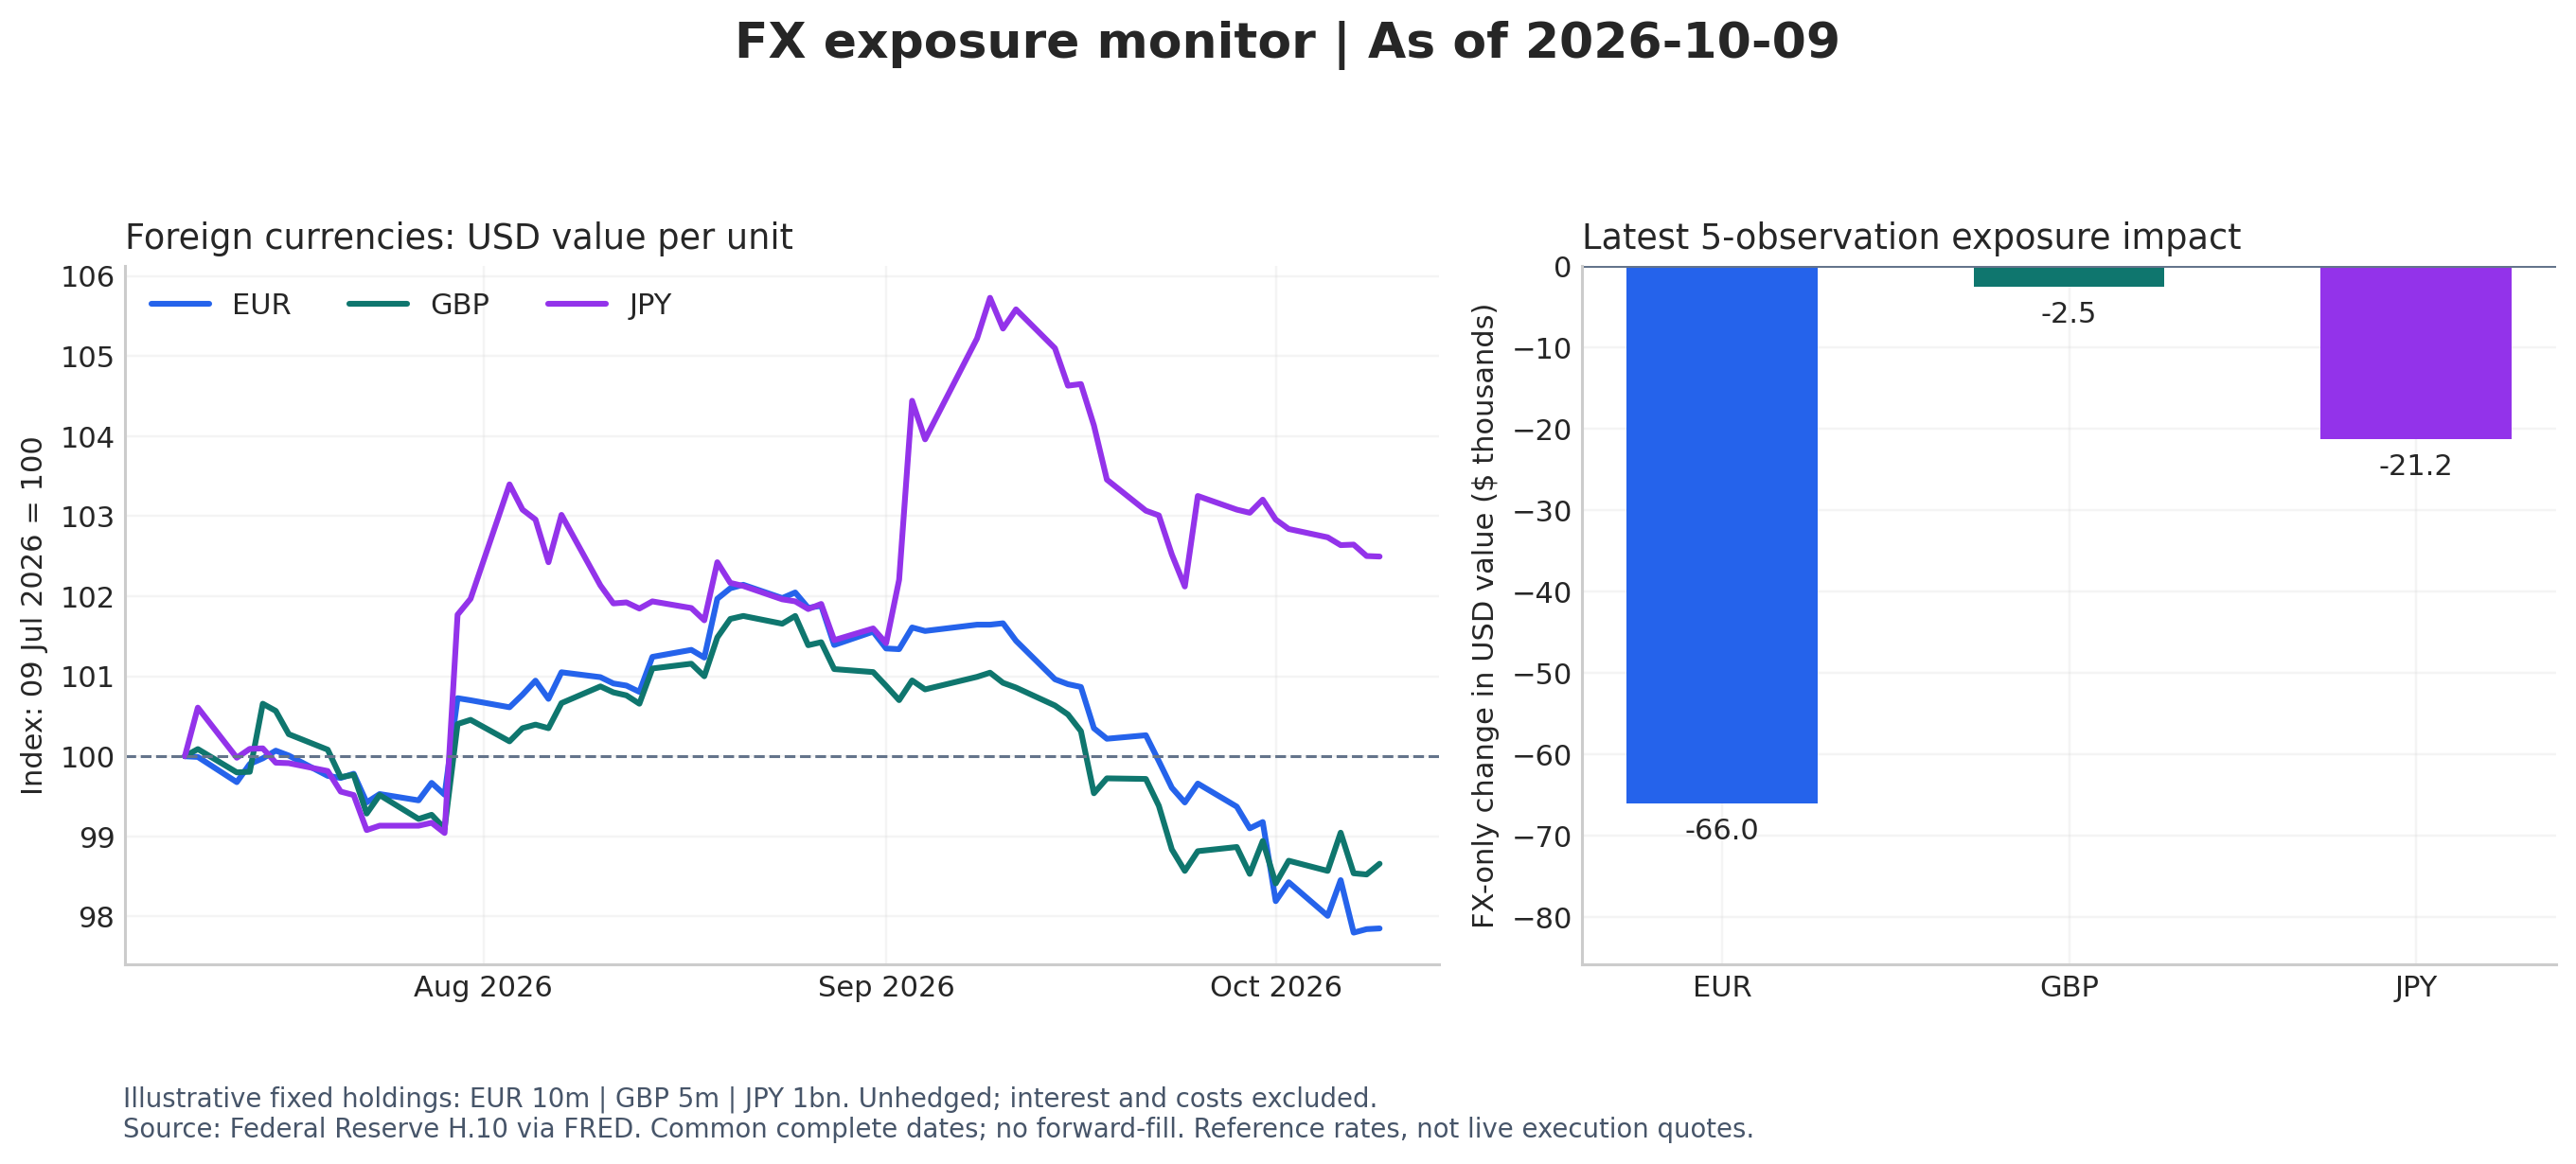

In [7]:
from IPython.display import Image, display
display(Image(filename=str(OUT / 'fx_exposure_monitor.png')))


## 7. Save the insight memo and close the database

The saved memo distinguishes observed FX moves from assumed exposures and asks for client information before discussing hedging.

In [8]:
week_total = totals.loc[totals['observations'] == 5].iloc[0]
largest = weekly.loc[weekly['fx_translation_change_usd'].abs().idxmax()]
lines = [f'# FX client insight memo | {AS_OF}', '',
    '**Scenario:** A hypothetical USD-reporting investor holds constant unhedged cash balances of EUR 10m, GBP 5m and JPY 1bn.', '',
    f"From {week_total['previous_date']} to {AS_OF}, their combined USD value changed by "
    f"${week_total['fx_translation_change_usd']:+,.0f} "
    f"({week_total['portfolio_fx_return_pct']:+.3f}%) due solely to FX translation. "
    f"Latest combined value: ${week_total['current_value_usd']:,.0f}.", '',
    f"The largest absolute currency contribution was {largest.name}: "
    f"${largest['fx_translation_change_usd']:+,.0f}. This reflects both exposure size and the currency's return.", '',
    '| Currency | 5-observation FX return | FX-only USD change |', '|---|---:|---:|']
for c, r in weekly.iterrows():
    lines.append(f"| {c} | {r['fx_return_pct']:+.3f}% | ${r['fx_translation_change_usd']:+,.0f} |")
lines += ['', '**Client conversation:** Confirm whether balances are assets, liabilities or future cash flows; establish hedge coverage, timing and the reporting currency. Use the attribution to prioritize the exposure review. It does not by itself justify a trade.', '',
    '**Limits:** Hypothetical fixed holdings; no flows, interest, asset-price movements, hedges or transaction costs. The calculation is a spot-translation estimate, not realized or accounting P&L. Reference rates are not executable quotes. Missing dates are excluded consistently but not fully reconciled to a publication calendar. This is descriptive analysis, not a forecast.']
(OUT / 'client_insight_memo.md').write_text('\n'.join(lines), encoding='utf-8')
conn.close()
print('\nDeliverables saved to:', OUT)



Deliverables saved to: /workspace/scratch/5752a39048ae/bny_task2/outputs
